**1. Setup**

In [9]:
!pip install -U ultralytics remotezip
import ultralytics
ultralytics.checks()

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 4.8/112.6 GB disk)


**2. Configure & mount to Google Drive**

Gestures used: dislike, fist, like, stop, one.

In [10]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path

CLASSES = ["dislike", "fist", "like", "one", "stop", "no_gesture"]
TRAIN_PER_CLASS = 1000
VAL_PER_CLASS = 200
IMG_SIZE = 640

WORK = Path("/content/hagrid_yolo")
SAVE = Path("/content/drive/MyDrive/hgr-game-control")
WORK.mkdir(parents=True, exist_ok=True)
SAVE.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
#temp: delete after initial train
TRAIN_PER_CLASS = 300
VAL_PER_CLASS = 60
print(TRAIN_PER_CLASS, VAL_PER_CLASS)

300 60


**3. Annotate dataset**

Gesture classes pulled from [HaGRID GitHub repo](https://github.com/hukenovs/hagrid).

In [16]:
#temp clean up after stopping initial overly large run
for p in (WORK/"images").rglob("*.jpg"):
    try:
        Image.open(p).verify()
    except Exception:
        p.unlink()
        (WORK/"labels"/p.parent.name/f"{p.stem}.txt").unlink(missing_ok=True)
        print("removed", p.name)

In [4]:
!wget -q -O /content/annotations.zip "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid_v2/annotations_with_landmarks/annotations.zip"
!unzip -q -o /content/annotations.zip -d /content/hagrid_ann

import json
ann_root = Path("/content/hagrid_ann")

def find_ann(split, cls):
    hits = list(ann_root.rglob(f"{split}/{cls}.json"))
    assert hits, f"no annotation file for {split}/{cls}"
    return hits[0]

ann = json.load(open(find_ann("train", "like")))
key = next(iter(ann))
print(key)
print({k: v for k, v in ann[key].items() if k != "hand_landmarks"})

replace /content/hagrid_ann/annotations/test/peace.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/two_up.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: a
error:  invalid response [a]
replace /content/hagrid_ann/annotations/test/two_up.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: a
error:  invalid response [a]
replace /content/hagrid_ann/annotations/test/two_up.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/stop_inverted.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/three.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/stop.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/rock.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/three2.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/hagrid_ann/annotations/test/dislike.json? 

**4. Convert labels**

HaGRID gives top-left box corner coordinates (x,y), but YOLO takes center coordinates (cx,cy). Convert cx = x + w/2 and cy = y + h/2.

In [18]:
import io, random
from PIL import Image
from remotezip import RemoteZip
from tqdm.auto import tqdm

OLD = "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/hagrid_dataset_new_554800/hagrid_dataset"
V2  = "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid_v2/hagrid_v2_zip"
ZIP_URLS = {
    "dislike": f"{OLD}/dislike.zip", "fist": f"{OLD}/fist.zip",
    "like": f"{OLD}/like.zip",       "one": f"{V2}/one.zip",
    "stop": f"{OLD}/stop.zip",       "no_gesture": f"{V2}/no_gesture.zip",
}
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}

def yolo_lines(entry):    #bbox conversion from corner to center
    lines = []
    for (x, y, w, h), label in zip(entry["bboxes"], entry["labels"]):
        if label not in CLASS_TO_ID:
            continue
        lines.append(f"{CLASS_TO_ID[label]} {x + w/2:.6f} {y + h/2:.6f} {w:.6f} {h:.6f}")
    return lines

#def pull_split(cls, split, n, seed=0):    #shuffle images
#    ann = json.load(open(find_ann(split, cls)))
#    keys = sorted(ann)
#    random.Random(seed).shuffle(keys)
#    img_dir = WORK / "images" / split
#    lbl_dir = WORK / "labels" / split
#    img_dir.mkdir(parents=True, exist_ok=True)
#    lbl_dir.mkdir(parents=True, exist_ok=True)
#    done = 0
#    with RemoteZip(ZIP_URLS[cls]) as z:
#        members = {Path(m).stem: m for m in z.namelist()
#                   if m.lower().endswith((".jpg", ".jpeg"))}
#        for key in keys:
#           if done >= n:
#               break
#           lines = yolo_lines(ann[key])
#           if key not in members or not lines:
#               continue
#            img = Image.open(io.BytesIO(z.read(members[key]))).convert("RGB")
#            img.thumbnail((IMG_SIZE, IMG_SIZE))
#            img.save(img_dir / f"{cls}_{key}.jpg", quality=90)
#            (lbl_dir / f"{cls}_{key}.txt").write_text("\n".join(lines))
#            done += 1
#    return done
#
#for cls in tqdm(CLASSES):
#    t = pull_split(cls, "train", TRAIN_PER_CLASS)
#    v = pull_split(cls, "val", VAL_PER_CLASS)
#    print(cls, "train:", t, "val:", v)

import threading
from concurrent.futures import ThreadPoolExecutor

for split in ["train", "val"]:
    (WORK/"images"/split).mkdir(parents=True, exist_ok=True)
    (WORK/"labels"/split).mkdir(parents=True, exist_ok=True)

tls = threading.local()
def get_zip(url):
    if getattr(tls, "url", None) != url:
        tls.z, tls.url = RemoteZip(url), url
    return tls.z

def plan(cls, split, n, seed=0):
    ann = json.load(open(find_ann(split, cls)))
    keys = sorted(ann)
    random.Random(seed).shuffle(keys)
    with RemoteZip(ZIP_URLS[cls]) as z:
        members = {Path(m).stem: m for m in z.namelist()
                   if m.lower().endswith((".jpg", ".jpeg"))}
    items = []
    for key in keys:
        lines = yolo_lines(ann[key])
        if key in members and lines:
            items.append((cls, split, key, members[key], lines))
        if len(items) >= n:
            break
    return items

def fetch_one(item):
    cls, split, key, member, lines = item
    out = WORK/"images"/split/f"{cls}_{key}.jpg"
    if not out.exists():
        img = Image.open(io.BytesIO(get_zip(ZIP_URLS[cls]).read(member))).convert("RGB")
        img.thumbnail((IMG_SIZE, IMG_SIZE))
        tmp = out.with_suffix(".tmp")
        img.save(tmp, "JPEG", quality=90)
        tmp.rename(out)
    (WORK/"labels"/split/f"{cls}_{key}.txt").write_text("\n".join(lines))

for cls in CLASSES:
    items = plan(cls, "train", TRAIN_PER_CLASS) + plan(cls, "val", VAL_PER_CLASS)
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(tqdm(ex.map(fetch_one, items), total=len(items), desc=cls))

dislike:   0%|          | 0/360 [00:00<?, ?it/s]

fist:   0%|          | 0/360 [00:00<?, ?it/s]

like:   0%|          | 0/360 [00:00<?, ?it/s]

one:   0%|          | 0/360 [00:00<?, ?it/s]

stop:   0%|          | 0/360 [00:00<?, ?it/s]

no_gesture:   0%|          | 0/360 [00:00<?, ?it/s]

In [14]:
print(len(list((WORK/"images"/"train").glob("*.jpg"))), "train images saved") #see number of images, ran after 12min = 459 train images saved

459 train images saved


**5. View data**

Visually verify classifications are correct and boxes are not shifted.

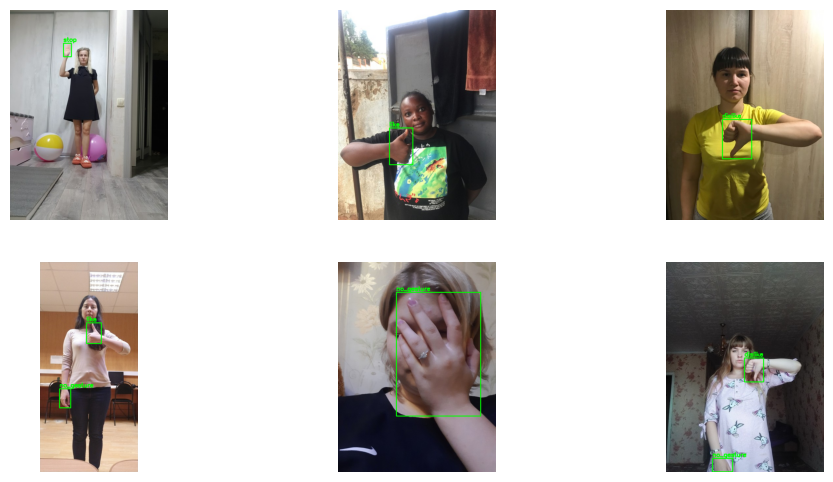

In [19]:
import cv2, matplotlib.pyplot as plt

def show_samples(split="train", n=6):
    paths = random.sample(sorted((WORK/"images"/split).glob("*.jpg")), n)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for ax, p in zip(axes.ravel(), paths):
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        for line in (WORK/"labels"/split/f"{p.stem}.txt").read_text().splitlines():
            c, cx, cy, w, h = line.split()
            cx, cy, w, h = float(cx)*W, float(cy)*H, float(w)*W, float(h)*H
            p1 = (int(cx - w/2), int(cy - h/2))
            p2 = (int(cx + w/2), int(cy + h/2))
            cv2.rectangle(im, p1, p2, (0, 255, 0), 2)
            cv2.putText(im, CLASSES[int(c)], (p1[0], max(p1[1] - 5, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        ax.imshow(im); ax.axis("off")
    plt.show()

show_samples()

**6. Dataset configuration**

In [20]:
yaml_text = f"path: {WORK}\ntrain: images/train\nval: images/val\nnames:\n"
yaml_text += "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES))
(WORK / "data.yaml").write_text(yaml_text)
print(yaml_text)

path: /content/hagrid_yolo
train: images/train
val: images/val
names:
  0: dislike
  1: fist
  2: like
  3: one
  4: stop
  5: no_gesture



**7. Training smoke test**

In [21]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")    #pretrained on COCO
results = model.train(
    data=str(WORK / "data.yaml"),
    epochs=2,
    imgsz=640,
    batch=16,
    workers=2,
    project=str(SAVE / "runs"),
    name="smoke_test",
)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hagrid_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_test-2, nbs=64, nms=None, opset=None, optimize=False,

**8. Back up dataset to Drive**

In [22]:
import shutil
shutil.make_archive(str(SAVE / "hagrid_subset"), "zip", WORK)

'/content/drive/MyDrive/hgr-game-control/hagrid_subset.zip'

**9. Real training run**

In [23]:
model = YOLO("yolo26n.pt")
results = model.train(
    data=str(WORK / "data.yaml"),
    epochs=50,
    patience=10,
    imgsz=640,
    batch=32,
    workers=2,
    project=str(SAVE / "runs"),
    name="gestures_n",
)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hagrid_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gestures_n, nbs=64, nms=None, opset=None, optimize=False, 

**10. Retrieve results**

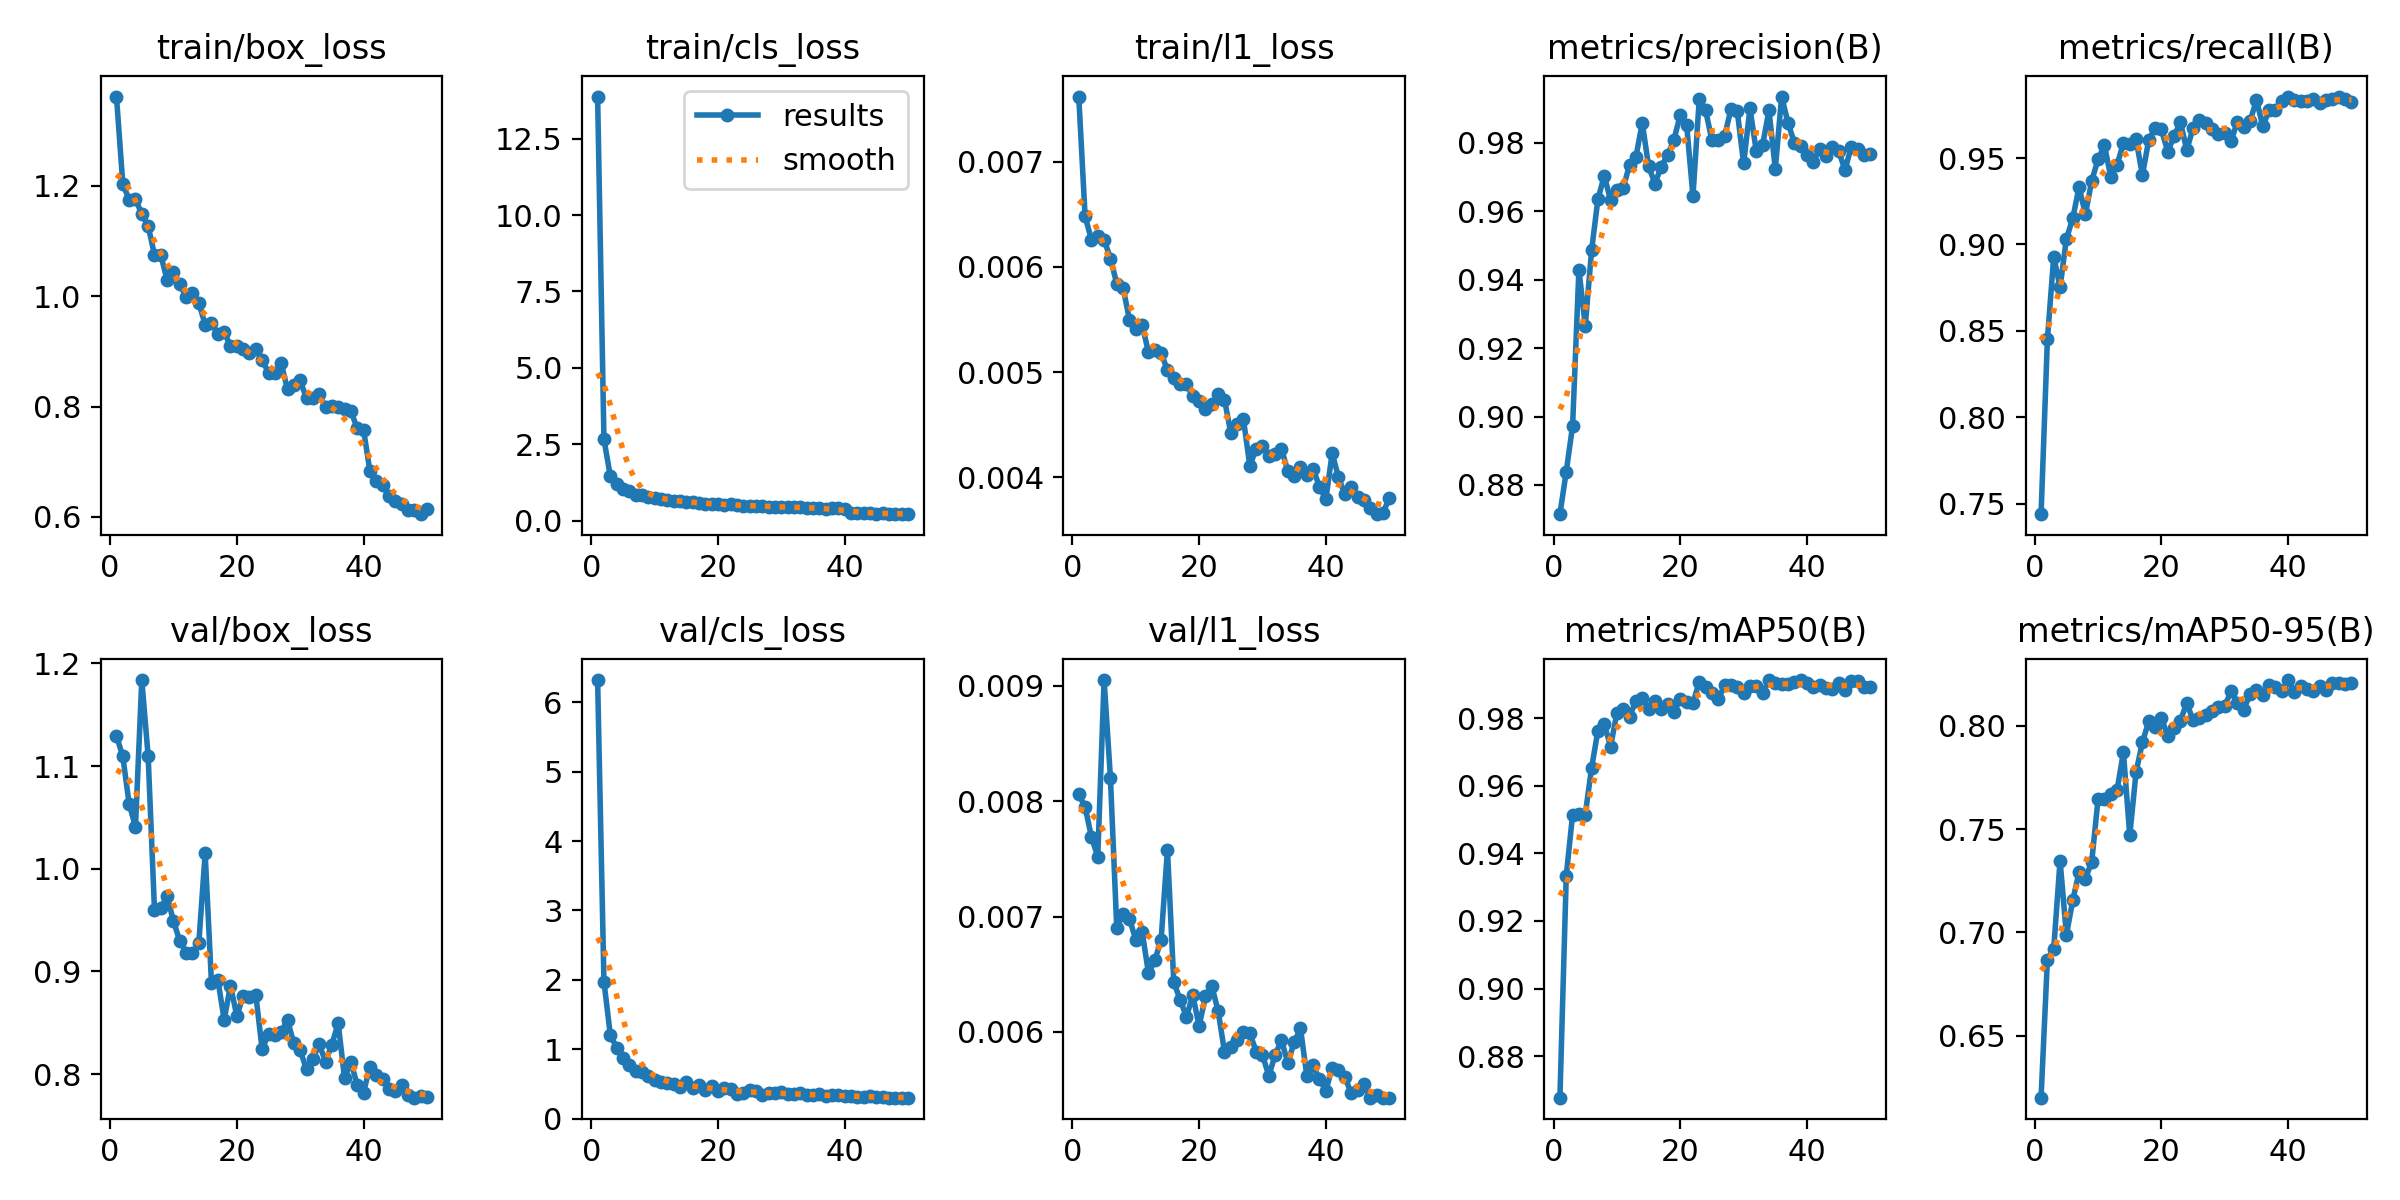

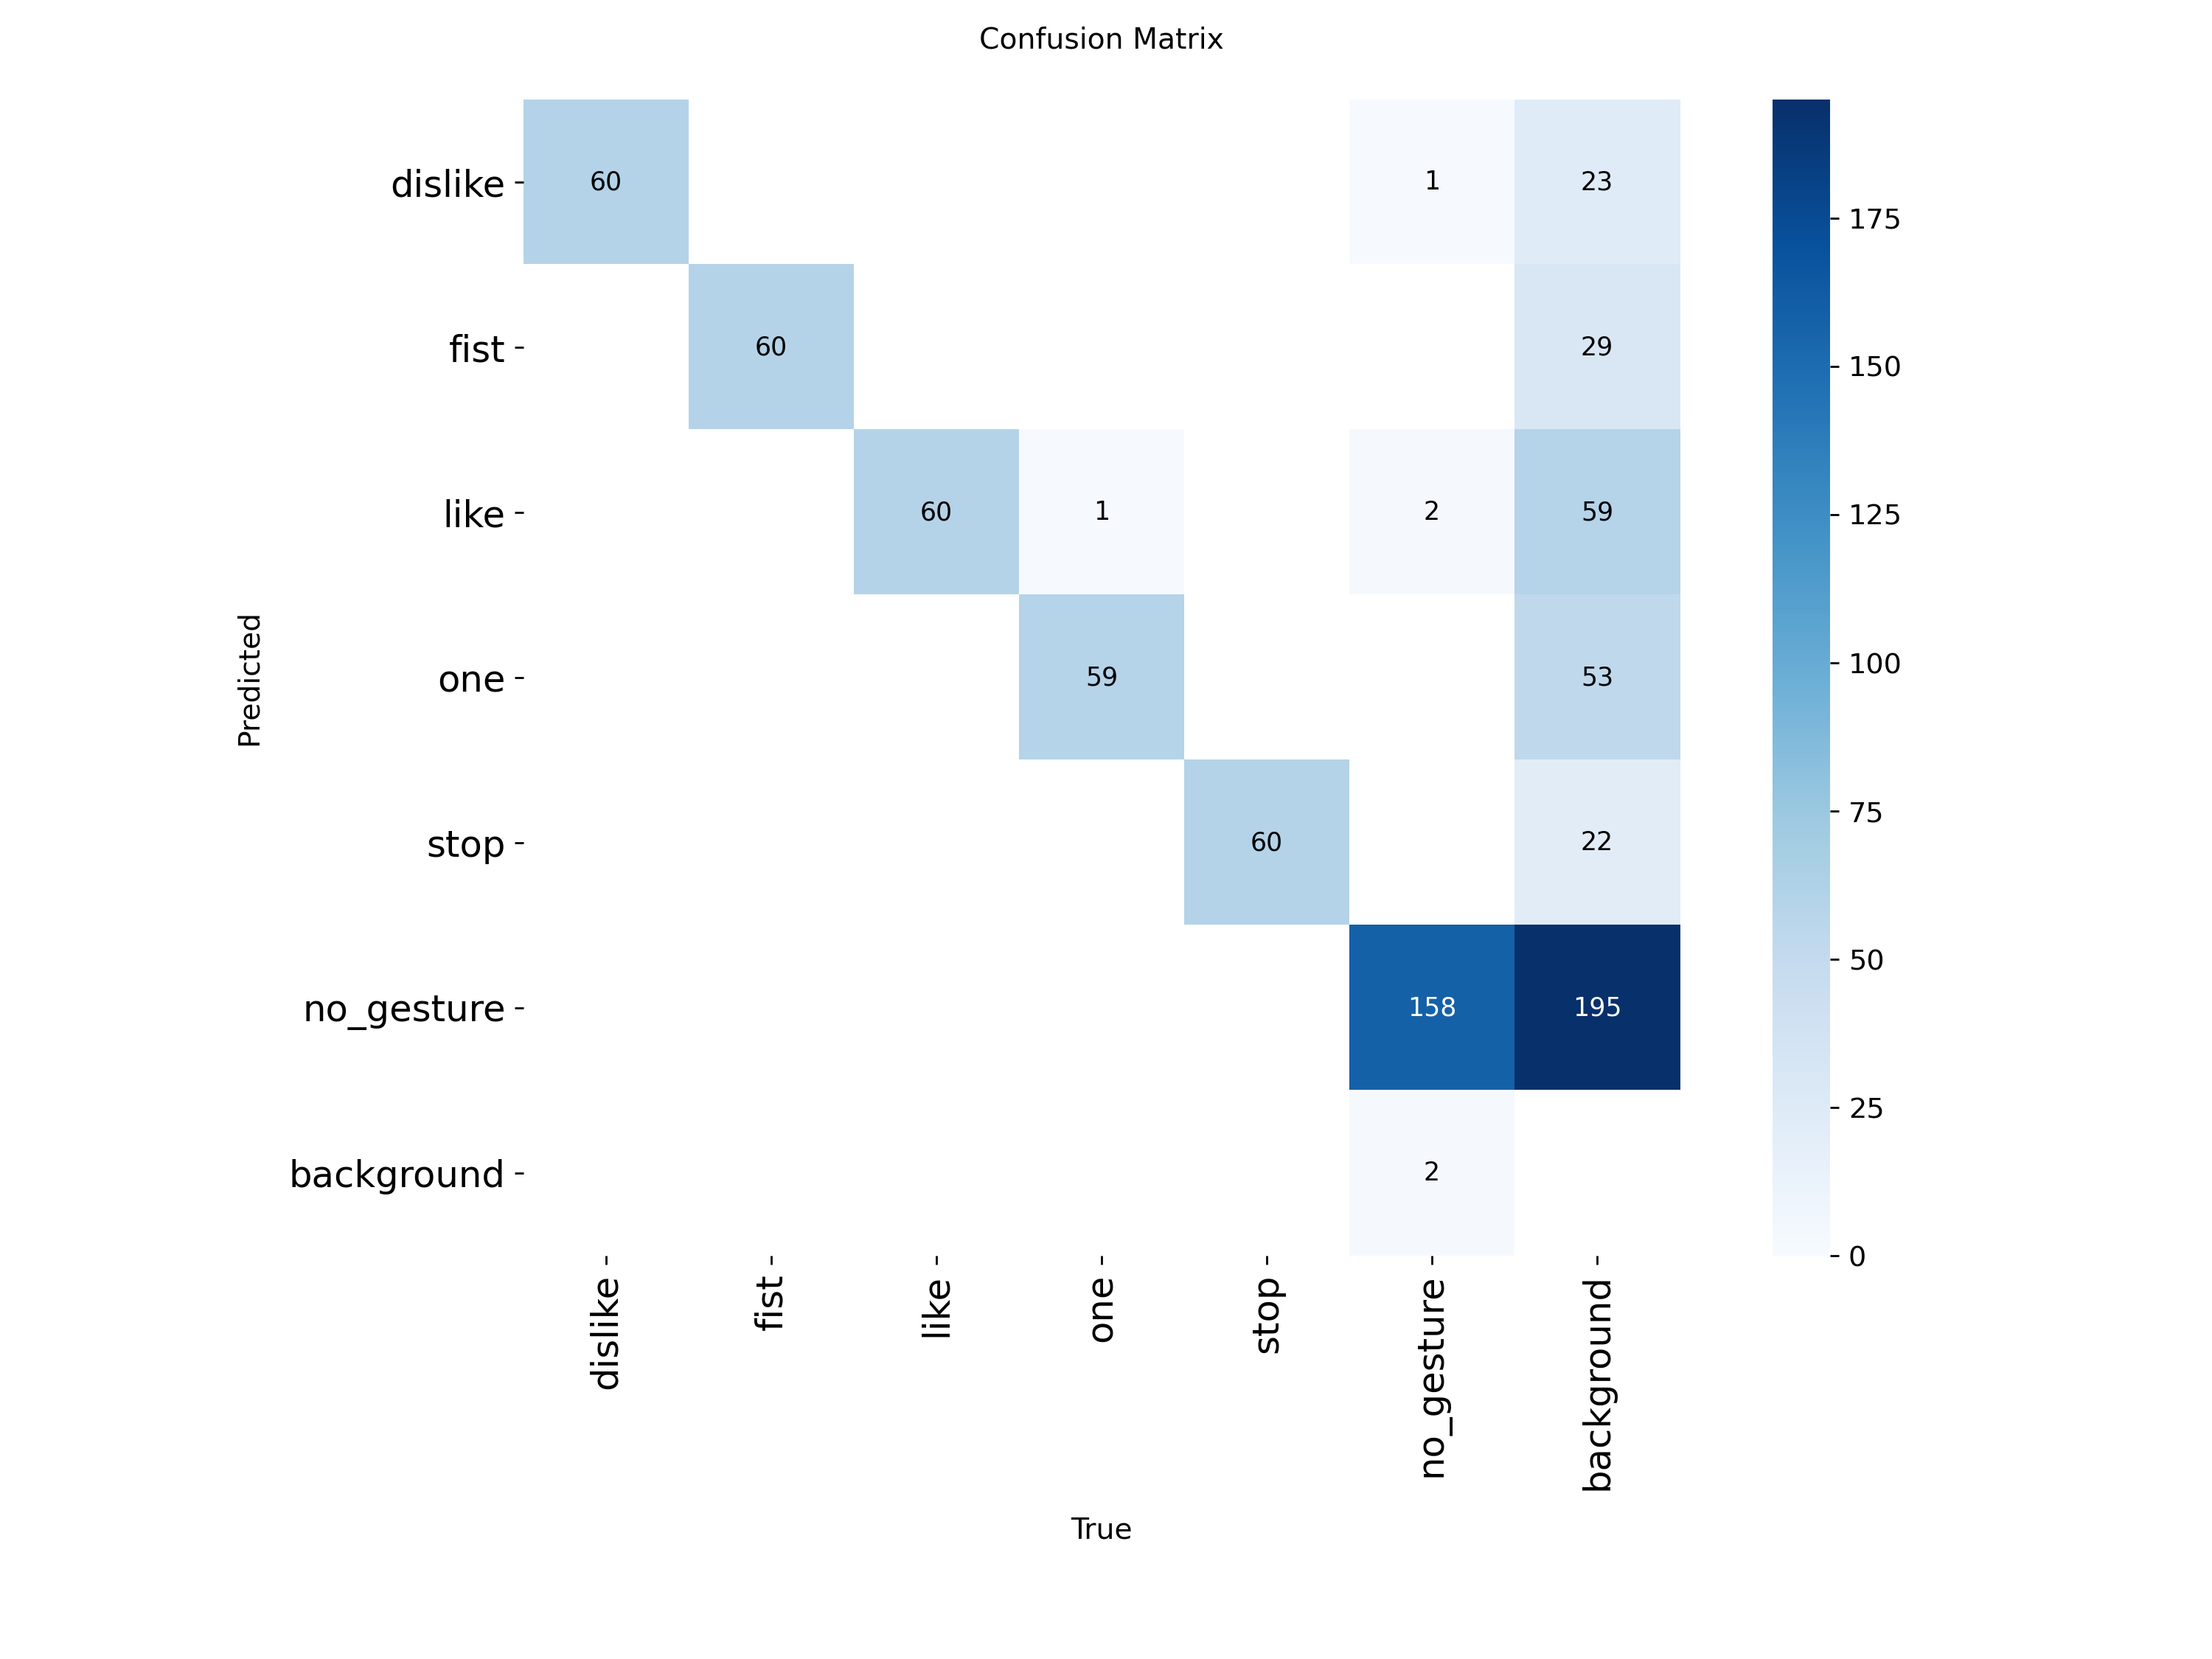

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1718.4±521.6 MB/s, size: 59.1 KB)
val: Scanning /content/hagrid_yolo/labels/val.cache... 360 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 360/360 100.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 5.4it/s 4.3s
                   all        360        463      0.977      0.984       0.99      0.824
               dislike         60         60      0.974          1      0.995      0.847
                  fist         60         60      0.978          1      0.995      0.841
                  like         60         60      0.959          1      0.992      0.861
                   one         60         60          1      0.992      0.995      0.847
                  stop         60         

In [24]:
from IPython.display import Image as IPImage, display

run = Path(model.trainer.save_dir)
display(IPImage(filename=str(run / "results.png")))
display(IPImage(filename=str(run / "confusion_matrix.png")))

best = YOLO(run / "weights" / "best.pt")
metrics = best.val()
print("mAP50:", metrics.box.map50, " mAP50-95:", metrics.box.map)

**11. Back up dataset**

In [25]:
import shutil
shutil.make_archive(str(SAVE / "hagrid_subset"), "zip", WORK)
!ls -lh "{SAVE}"

total 124M
-rw------- 1 root root 124M Nov 14 23:37 hagrid_subset.zip
drwx------ 5 root root 4.0K Nov 14 23:00 runs
